<a href="https://colab.research.google.com/github/AdityaR28/OSS4008A---Introduction-to-Remote-Sensing-and-Applications/blob/main/students/devon_clermont-gauer/code/water_dataset_export.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 02: Water Dataset Export (Project 11)
#**Name:** Devon Clermont-Gauer

#Builds training data for the water segmentation model: Sentinel-2 imagery (5 bands) paired with Dynamic World water masks for 12 Canadian regions, exported to Google Drive and cut into 256×256 tiles, split by region into train, validation and test.

#**Data:** Sentinel-2 SR Harmonized (Copernicus), Dynamic World V1 (Google/WRI), via Google Earth Engine.

#**How to run:** set your project ID in Cell 1, run Cells 1–5, wait for all exports to show COMPLETED, then run Cells 6–7.

In [10]:
# Cell 1: Earth Engine login and region list

import ee        # Earth Engine Python API: access to Google's satellite data and servers
import geemap    # interactive maps for Earth Engine inside notebooks

# Log in to Earth Engine (opens a Google sign-in prompt the first time)
ee.Authenticate()

# Connect to Earth Engine using my Google Cloud project
ee.Initialize(project='causal-sky-509317-u9')                    # replace with your Cloud project ID

# Connection test: ask Earth Engine's servers to send back a word
print('Earth Engine says:', ee.String('hello').getInfo())

# Sample regions across different Canadian landscapes.
# Format: (name, split, [lon_min, lat_min, lon_max, lat_max], landscape type)
#   - name:  short label, used in file names
#   - split: which dataset the whole region goes to (train / val / test),
#            so the model is always tested on places it never trained on
#   - box:   west, south, east, north edges in degrees (longitude first)
#   - type:  the landscape it represents, for documentation
REGIONS = [
    # Training regions: varied landscapes so the model learns many kinds of water
    ('algonquin',        'train', [-78.60, 45.50, -78.30, 45.70], 'Shield lakes, ON'),
    ('prairie_potholes', 'train', [-106.20, 52.10, -105.90, 52.30], 'Prairie ponds, SK'),
    ('quebec_city',      'train', [-71.40, 46.75, -71.10, 46.95], 'St. Lawrence + urban, QC'),
    ('fraser_delta',     'train', [-123.20, 49.05, -122.90, 49.25], 'River delta + urban, BC'),
    ('mackenzie_delta',  'train', [-134.60, 68.30, -134.20, 68.45], 'Tundra lakes, NT'),
    ('peace_athabasca',  'train', [-111.60, 58.60, -111.20, 58.80], 'Wetlands, AB'),
    ('lake_louise',      'train', [-116.30, 51.35, -116.10, 51.47], 'Mountain lakes + shadows, AB'),
    ('toronto',          'train', [-79.50, 43.60, -79.25, 43.72], 'Urban + Great Lake shore, ON'),

    # Validation regions: checked during training to track progress and catch overfitting
    ('ottawa',           'val',   [-75.85, 45.35, -75.55, 45.50], 'River + urban, ON'),
    ('north_manitoba',   'val',   [-97.00, 55.70, -96.60, 55.90], 'Northern Shield lakes, MB'),

    # Test regions: used once at the end for the final score (corrected in labelme)
    ('kejimkujik',       'test',  [-65.35, 44.30, -65.05, 44.45], 'Forest lakes, NS'),
    ('iqaluit',          'test',  [-68.65, 63.70, -68.35, 63.80], 'Arctic tundra, NU'),
]

# Confirm how many regions are defined
print(len(REGIONS), 'regions defined')

Earth Engine says: hello
12 regions defined


In [11]:
# Cell 2: Sentinel-2 composite + Dynamic World water mask, stacked into one image
START, END = '2024-06-01', '2024-09-30'        # summer: no ice
BANDS = ['B2', 'B3', 'B4', 'B8', 'B11']        # blue, green, red, NIR, SWIR

def build_stack(bbox):
    region = ee.Geometry.Rectangle(bbox)

    # Satellite image: median of all low-cloud summer images (removes most clouds)
    s2 = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
          .filterBounds(region)
          .filterDate(START, END)
          .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20))
          .select(BANDS)
          .median())

    # Label: most common Dynamic World class over the same dates; 1 = water, 0 = not
    water = (ee.ImageCollection('GOOGLE/DYNAMICWORLD/V1')
             .filterBounds(region)
             .filterDate(START, END)
             .select('label')
             .mode()
             .eq(0)
             .rename('water'))

    # Stack: 5 image bands + 1 mask band, whole numbers, empty pixels set to 0
    return s2.addBands(water).toInt16().unmask(0).clip(region), region

In [12]:
# Cell 3: check a region visually before exporting
name, split, bbox, desc = REGIONS[0]          # change the index (0-11) to check other regions
stack, region = build_stack(bbox)

m = geemap.Map(basemap='Esri.WorldImagery')   # Esri background (OpenStreetMap tiles are blocked in Colab)
m.centerObject(region, 11)
m.addLayer(stack, {'bands': ['B4', 'B3', 'B2'], 'min': 0, 'max': 3000}, 'Sentinel-2')
m.addLayer(stack.select('water').selfMask(), {'palette': ['00ffff']}, 'Water mask')
print(name, '|', split, '|', desc)
m

algonquin | train | Shield lakes, ON


Map(center=[45.60003874374379, -78.44999999999945], controls=(WidgetControl(options=['position', 'transparent_…

In [ ]:
# Cell 4: start exports to Google Drive (runs on Google's servers)
# ⚠️ Starts 12 exports (several hours). Skip this cell if the exports already
#    exist in Drive (exports for this dataset completed Nov 7, 2026).
tasks = []
for name, split, bbox, desc in REGIONS:
    stack, region = build_stack(bbox)
    task = ee.batch.Export.image.toDrive(
        image=stack,
        description=f'{split}__{name}',   # split saved in the filename
        folder='water_regions',
        region=region,
        scale=10,                         # 10 m pixels
        crs='EPSG:3978',                  # Canada's standard map projection
        maxPixels=1e9)
    task.start()
    tasks.append(task)
    print('Started:', split, name)

Started: train algonquin
Started: train prairie_potholes
Started: train quebec_city
Started: train fraser_delta
Started: train mackenzie_delta
Started: train peace_athabasca
Started: train lake_louise
Started: train toronto
Started: val ottawa
Started: val north_manitoba
Started: test kejimkujik
Started: test iqaluit


In [ ]:
# Cell 5: check progress (re-run until all say COMPLETED)
for t in tasks:
    s = t.status()
    print(s['description'], '->', s['state'], s.get('error_message', ''))

In [13]:
# Cell 6: split each region into 256x256 tiles, sorted into train/val/test
from google.colab import drive
drive.mount('/content/drive')

import os, glob
import numpy as np
import rasterio
from rasterio.windows import Window

SRC = '/content/drive/MyDrive/water_regions'
OUT = '/content/drive/MyDrive/water_dataset'
T = 256   # tile size in pixels (2.56 km at 10 m)

counts = {}
for path in sorted(glob.glob(f'{SRC}/*.tif')):
    split, name = os.path.basename(path)[:-4].split('__')
    os.makedirs(f'{OUT}/{split}/images', exist_ok=True)
    os.makedirs(f'{OUT}/{split}/masks', exist_ok=True)

    with rasterio.open(path) as src:
        for r in range(0, src.height - T + 1, T):
            for c in range(0, src.width - T + 1, T):
                win = Window(c, r, T, T)
                data = src.read(window=win)           # shape (6, 256, 256)
                img, mask = data[:5], data[5:6]

                # Skip tiles that are mostly empty (outside the region or no data)
                if (img == 0).all(axis=0).mean() > 0.1:
                    continue

                tid = f'{name}_r{r}_c{c}'
                prof = src.profile.copy()
                prof.update(width=T, height=T, transform=src.window_transform(win))

                prof.update(count=5)
                with rasterio.open(f'{OUT}/{split}/images/{tid}.tif', 'w', **prof) as dst:
                    dst.write(img)
                prof.update(count=1)
                with rasterio.open(f'{OUT}/{split}/masks/{tid}.tif', 'w', **prof) as dst:
                    dst.write(mask)

                counts[split] = counts.get(split, 0) + 1

print('Tiles per split:', counts)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Tiles per split: {'test': 68, 'train': 396, 'val': 112}


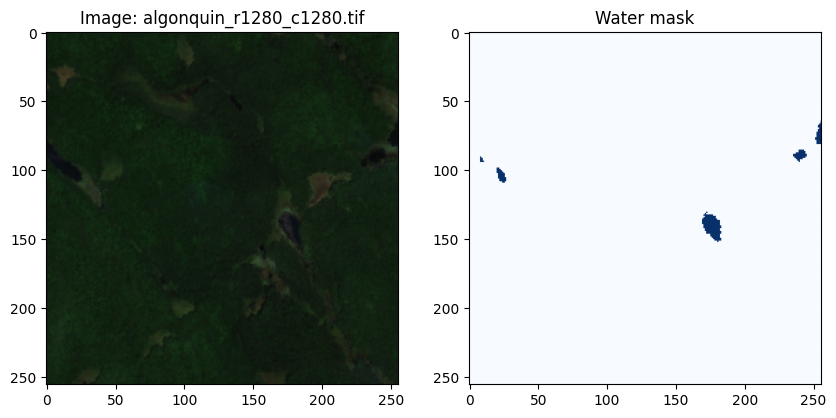

In [14]:
# Cell 7: show one image tile next to its water mask to confirm they line up
import matplotlib.pyplot as plt

files = sorted(glob.glob(f'{OUT}/train/images/*.tif'))
f = files[min(10, len(files) - 1)]            # pick a tile (change the number to see others)

with rasterio.open(f) as s:
    img = s.read([3, 2, 1]).transpose(1, 2, 0)   # red, green, blue for display
with rasterio.open(f.replace('/images/', '/masks/')) as s:
    mask = s.read(1)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(np.clip(img / 3000, 0, 1)); ax[0].set_title('Image: ' + os.path.basename(f))
ax[1].imshow(mask, cmap='Blues');        ax[1].set_title('Water mask')
plt.show()

In [15]:
# Cell 8: dataset summary — tiles and water percentage per region and split
from collections import defaultdict

stats = defaultdict(lambda: {'tiles': 0, 'water': 0.0})
for split in ['train', 'val', 'test']:
    for f in glob.glob(f'{OUT}/{split}/masks/*.tif'):
        region = os.path.basename(f).rsplit('_r', 1)[0]     # e.g. 'algonquin'
        with rasterio.open(f) as s:
            water_frac = s.read(1).mean()                    # share of pixels that are water
        stats[(split, region)]['tiles'] += 1
        stats[(split, region)]['water'] += water_frac

print(f"{'split':6} {'region':18} {'tiles':>6} {'water %':>8}")
for (split, region), v in sorted(stats.items()):
    print(f"{split:6} {region:18} {v['tiles']:>6} {100 * v['water'] / v['tiles']:>7.1f}%")

split  region              tiles  water %
test   iqaluit                15    31.9%
test   kejimkujik             53    14.0%
train  algonquin              68     8.1%
train  fraser_delta           62    10.6%
train  lake_louise            19     2.8%
train  mackenzie_delta        31    53.7%
train  peace_athabasca        61    19.9%
train  prairie_potholes       56     5.7%
train  quebec_city            67    10.7%
train  toronto                32    31.1%
val    north_manitoba         62    14.8%
val    ottawa                 50    11.6%


In [16]:
# Cell 9: make viewable PNG previews (image | mask side by side) for the shared Drive folder
# Self-contained: can run on its own in a fresh session.
from google.colab import drive
drive.mount('/content/drive')

import os, glob
import numpy as np
import rasterio
import matplotlib.pyplot as plt

OUT = '/content/drive/MyDrive/water_dataset'
PREV = f'{OUT}/previews'
os.makedirs(PREV, exist_ok=True)

for split in ['train', 'val', 'test']:
    for f in sorted(glob.glob(f'{OUT}/{split}/images/*.tif'))[::10]:   # every 10th tile
        with rasterio.open(f) as s:
            rgb = np.clip(s.read([3, 2, 1]).transpose(1, 2, 0) / 3000, 0, 1)   # natural colour
        with rasterio.open(f.replace('/images/', '/masks/')) as s:
            mask = s.read(1)

        fig, ax = plt.subplots(1, 2, figsize=(8, 4))
        ax[0].imshow(rgb);                 ax[0].set_title('Sentinel-2')
        ax[1].imshow(mask, cmap='Blues');  ax[1].set_title('Water mask')
        for a in ax:
            a.axis('off')
        name = os.path.basename(f)[:-4]
        fig.suptitle(f'{split} | {name}')
        fig.savefig(f'{PREV}/{split}__{name}.png', dpi=80, bbox_inches='tight')
        plt.close(fig)                     # don't display each figure in the notebook

print('Previews saved:', len(glob.glob(f'{PREV}/*.png')))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Previews saved: 59
